# Banking77: когда передавать обращение оператору

В первом сравнении предобученный DistilBERT оказался сильнее TF-IDF и небольшого Transformer с нуля. Теперь хочу понять, как использовать классификатор для маршрутизации: какая доля обращений проходит автоматически, сколько среди них ошибок и сколько занимает предсказание.

Новый запуск хранится в `reports/evaluation`; результаты первого сравнения в ноутбуках 01–05 сохранены отдельно. Полное обучение запускается из корня командой `PYTHONPATH=src python -m banking_intent.experiment`. Гиперпараметры DistilBERT оставлены прежними: длина 64, batch 16, lr 2e-5, не более трёх эпох.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent
REPORTS = ROOT / "reports/evaluation"
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (9, 4)}
)
pd.read_csv(REPORTS / "split_summary.csv")

,split,rows,classes
0,train,7996,77
1,tune,1000,77
2,policy,1000,77
3,test,3080,77


## Модель и порог выбираются отдельно

Обучающая часть осталась прежней: 7 996 обращений после удаления семи совпадений с официальным test. Validation из 2 000 строк разделена пополам. На tune выбираются n-gram для TF-IDF и эпоха DistilBERT; на policy выбирается порог уверенности. Официальные 3 080 тестовых обращений используются для отчёта после этих решений.

Среди порогов 0.00–1.00 с шагом 0.01 выбираю максимальное покрытие при accuracy не ниже 95% и хотя бы 100 принятых обращениях на policy. 95% — выбранный для эксперимента ориентир. На test он может не выполниться.

In [2]:
pd.read_csv(REPORTS / "tfidf_selection.csv").round(4)

,ngrams,training_seconds,accuracy,macro_f1
0,"(1, 1)",0.3048,0.858,0.8546
1,"(1, 2)",1.4029,0.848,0.8449


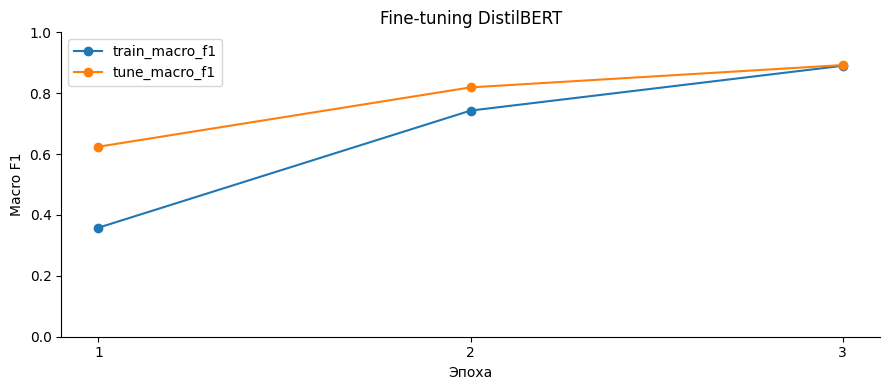

In [3]:
history = pd.read_csv(REPORTS / "distilbert_history.csv")
history.plot(x="epoch", y=["train_macro_f1", "tune_macro_f1"], marker="o")
plt.xlabel("Эпоха")
plt.ylabel("Macro F1")
plt.xticks(history.epoch)
plt.ylim(0, 1)
plt.title("Fine-tuning DistilBERT")
plt.tight_layout()
plt.show()

In [4]:
metrics = pd.read_csv(REPORTS / "metrics.csv")
metrics.query("split == 'test'").round(4)

,model,split,accuracy,macro_f1
2,tfidf,test,0.8653,0.8646
5,distilbert,test,0.9016,0.9019


## Покрытие и ошибки

При повышении порога больше обращений уходит оператору. Поэтому одной accuracy недостаточно: рядом показываю coverage — долю автоматически направленных обращений. На графике используются только policy-данные; test оценивается при уже выбранном пороге.

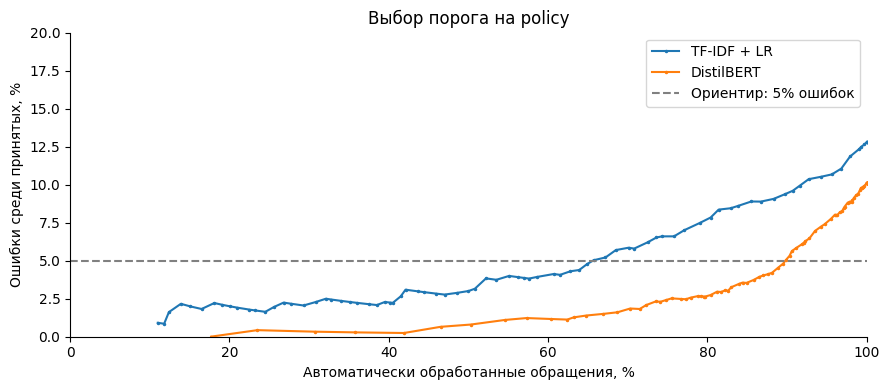

In [5]:
fig, ax = plt.subplots()
for model, label in [("tfidf", "TF-IDF + LR"), ("distilbert", "DistilBERT")]:
    curve = pd.read_csv(REPORTS / f"{model}_routing_curve.csv").query("accepted >= 100")
    ax.plot(
        curve.coverage * 100,
        curve.error_rate * 100,
        marker=".",
        markersize=3,
        label=label,
    )
ax.axhline(5, linestyle="--", color="gray", label="Ориентир: 5% ошибок")
ax.set(
    xlabel="Автоматически обработанные обращения, %",
    ylabel="Ошибки среди принятых, %",
    title="Выбор порога на policy",
    xlim=(0, 100),
    ylim=(0, 20),
)
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
routing = pd.read_csv(REPORTS / "routing.csv")
routing.round(4)

,model,split,threshold,rows,accepted,coverage,accepted_accuracy,wrongly_routed,handoff
0,tfidf,policy,0.33,1000,649,0.6490,0.9522,31,351
1,tfidf,test,0.33,3080,2034,0.6604,0.9597,82,1046
2,distilbert,policy,0.50,1000,895,0.8950,0.9520,43,105
3,distilbert,test,0.50,3080,2692,0.8740,0.9480,140,388


## Что происходит с неизвестными темами

Я добавил 40 коротких англоязычных фраз: 20 на посторонние темы и 20 про банковские услуги, которых нет среди 77 классов. Это небольшой составленный набор примеров, а не выборка реальных обращений. Он помогает увидеть уверенные ошибки, но не измеряет качество на всём потоке неизвестных тем.

In [7]:
ood = pd.read_csv(REPORTS / "ood_predictions.csv")
ood.groupby(["model", "group"]).agg(
    examples=("accepted", "size"), wrongly_accepted=("accepted", "sum")
)

examples  wrongly_accepted
model      group                                          
distilbert unrelated                  20                 5
           unsupported_banking        20                 5
tfidf      unrelated                  20                 3
           unsupported_banking        20                 2

In [8]:
ood.query("accepted").sort_values("confidence", ascending=False).head(8)

,text,group,model,predicted_category,confidence,accepted
55,I forgot the password to my game account.,unrelated,distilbert,passcode_forgotten,0.921130,True
44,Can you help me reset my email password?,unrelated,distilbert,passcode_forgotten,0.887852,True
71,How do I set up a trust fund for my child?,unsupported_banking,distilbert,age_limit,0.848233,True
53,I want to return a shirt I bought online.,unrelated,distilbert,request_refund,0.843747,True
66,How can I pay a cheque into my account?,unsupported_banking,distilbert,top_up_by_cash_or_cheque,0.829151,True
52,Why is my mobile signal so weak?,unrelated,distilbert,lost_or_stolen_phone,0.811554,True
79,How do I change the beneficiary of my life ins...,unsupported_banking,distilbert,beneficiary_not_allowed,0.708456,True
68,How do I transfer my pension to your bank?,unsupported_banking,distilbert,receiving_money,0.684334,True


## Разбор ошибок DistilBERT

Из ошибок на test случайно выбраны 60 примеров с seed=42. Для каждого записаны причина путаницы и короткий комментарий в `error_review.csv`. Это качественный разбор с помощью ИИ, а не новая эталонная разметка. Спорные случаи оставлены как спорные. После просмотра этих примеров модель и порог не менялись.

In [9]:
errors = pd.read_csv(REPORTS / "error_review.csv")
errors.reason.value_counts().to_frame("examples")

,examples
reason,
не хватает контекста,26
близкие интенты,12
пропущен явный признак,10
спорная метка,7
несколько намерений,5


In [10]:
pd.set_option("display.max_colwidth", 160)
errors[["text", "category", "predicted_category", "reason", "comment"]].head(8)

,text,category,predicted_category,reason,comment
0,"I am waiting patiently for a week now for the seller to get back to me and there has been no response, could you please help me further with getting my mone...",Refund_not_showing_up,reverted_card_payment?,не хватает контекста,"Пользователь ждёт ответа продавца; не сказано, был ли возврат уже оформлен."
1,How can I perform a dual money transferring from one account to another?,transfer_into_account,receiving_money,не хватает контекста,"Неясно, что означает dual transfer и между какими счетами нужен перевод."
2,what is the identity check?,why_verify_identity,verify_my_identity,близкие интенты,Общий вопрос об identity check можно отнести к объяснению проверки или к её процедуре.
3,My non-physical card will not work,virtual_card_not_working,card_not_working,пропущен явный признак,Non-physical указывает на виртуальную карту; модель выбрала общий отказ карты.
4,So I just put my top-up into the card and it hasn't changed.,pending_top_up,top_up_failed,не хватает контекста,"Баланс не изменился, но статус пополнения — pending или failed — не указан."
5,"I am a new customer, and I happened to look at my app and there is a charge I am not familiar with. Could you tell me why the extra charge is there?",extra_charge_on_statement,direct_debit_payment_not_recognised,не хватает контекста,"Есть лишнее списание, но из текста нельзя установить его тип."
6,Am I allowed to use any card to make a payment?,visa_or_mastercard,card_acceptance,не хватает контекста,"Any card не уточняет платёжную систему, эмитента или место оплаты."
7,"I don't understand how to top up my account, can you please explain the process?",transfer_into_account,topping_up_by_card,не хватает контекста,Способ пополнения не назван; карточное пополнение и перевод на счёт возможны оба.


## Скорость и размер

Обе модели измеряются на CPU Apple M4, 16 GB. Время включает обработку текста и получение вероятностей, но не загрузку модели с диска. Для batch=1 и batch=32 сделано по 5 прогревов и 50 замеров. Показаны медиана и p95; batch latency и время на один текст — разные величины. Замер выполнен отдельно от обучения.

In [11]:
latency = pd.read_csv(REPORTS / "latency.csv")
latency.round(3)

,model,batch_size,repeats,median_ms,p95_ms,median_ms_per_text
0,tfidf,1,50,0.209,0.226,0.209
1,tfidf,32,50,0.324,0.365,0.010
2,distilbert,1,50,11.210,12.062,11.210
3,distilbert,32,50,215.281,233.094,6.728


In [12]:
environment = json.loads((REPORTS / "environment.json").read_text())
pd.Series(
    {name: size / 1024**2 for name, size in environment["model_sizes_bytes"].items()},
    name="Размер файлов, MiB",
).to_frame()

,"Размер файлов, MiB"
tfidf,0.827442
distilbert,256.551294


## Вывод

DistilBERT получил test macro F1 **0,9019** против **0,8646** у TF-IDF. При пороге 0,50 он принимает 87,4% обращений с точностью 94,8%; ориентир 95% на test немного не выполнен. TF-IDF при пороге 0,33 принимает 66,0% обращений с точностью 96,0%. Поэтому выбор зависит и от допустимой нагрузки на оператора.

В 60 разобранных ошибках чаще всего не хватало контекста — 26 случаев. Ещё 12 отнесены к близким интентам, 10 — к пропущенным явным подсказкам, 7 — к спорным меткам, 5 — к нескольким намерениям. Эти категории субъективны; исходные метки сохранены.

Порог не защищает от всех неизвестных тем: DistilBERT принял 10 из 40 составленных примеров, TF-IDF — 5. Для применения за пределами Banking77 сначала потребовалась бы проверка на реальном потоке, включая обращения без подходящего класса.